<a href="https://colab.research.google.com/github/OJB-Quantum/Qiskit-Metal-to-Litho/blob/main/Python%20Code_Qiskit%20Metal_Designs/TwoTransmonsWithMeander.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bus Resonator Coupler (transmon-transmon)

> 💡 **Running in Colab or Binder?** Skip the desktop GUI install — the cell below grabs the lite (no-Qt) wheel, and `qm.gui(design)` auto-picks an inline matplotlib viewer with the same API (`gui.rebuild()`, `gui.screenshot()`, `gui.edit_component(...)`) as the desktop `MetalGUI`.

In [33]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
!pip install -q quantum-metal

> 💡 **Using this tutorial without the Qt GUI**
>
> This tutorial uses the desktop `MetalGUI`. To follow along on Colab, Binder, JupyterHub, or any environment where Qt isn't available, **replace any `gui.rebuild()` / `gui.screenshot()` call with `qm.view(design)`** — it renders the design to a matplotlib `Figure` you can display inline or save with `fig.savefig(...)`.
>
> See [1.1 Quick start](https://qiskit-community.github.io/qiskit-metal/tut/1-Overview/1.1-Quick-start.html) for a complete runnable walkthrough and [`docs/headless-usage.rst`](https://qiskit-community.github.io/qiskit-metal/headless-usage.html) for the full reference.

In [34]:
import sys
import tempfile
import urllib.request
import warnings
import logging
import base64
from pathlib import Path
from IPython.display import display, HTML, Image

import matplotlib.pyplot as plt
import qiskit_metal as metal
from qiskit_metal.validation import DEFAULT_RULES, SHAPE_RULES, validate

# Global Configurations
plt.rcParams['figure.dpi'] = 250
warnings.filterwarnings("ignore", category=FutureWarning)
HEADLESS = True
BUTTON_BACKGROUND_HEX = "#0078D7"
BUTTON_FOREGROUND_HEX = "#FFFFFF"
GDS_FILENAME = "twotransmons.gds"
TARGET_DPI = 250
ADJUSTABLE_STRATEGY = "box"

In [50]:
def create_download_button(file_path: Path) -> None:
    """Generates an HTML download button for the exported GDS file."""
    with open(file_path, "rb") as file_pointer:
        binary_content = file_pointer.read()

    encoded_string = base64.b64encode(binary_content).decode()
    html_payload = f'''
    <a download="{file_path.name}"
       href="data:application/octet-stream;base64,{encoded_string}"
       style="display: inline-block; padding: 12px 24px;
              background-color: {BUTTON_BACKGROUND_HEX}; color: {BUTTON_FOREGROUND_HEX};
              text-decoration: none; border-radius: 4px;
              font-family: Arial, sans-serif; font-weight: bold;">
        Download {file_path.name}
    </a>
    '''
    display(HTML(html_payload))

def save_headless_screenshot(gui_object) -> None:
    import matplotlib.pyplot as plt
    plt.rcParams['figure.dpi'] = TARGET_DPI

    # 1. Render first
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="Ignoring fixed y limits.*", category=UserWarning)
        gui_object.screenshot()

    active_figure = gui_object.figure
    if active_figure and active_figure.axes:
        active_axes = active_figure.axes[0]
        active_axes.grid(False) # Remove grid
        active_axes.set_aspect("equal", adjustable=ADJUSTABLE_STRATEGY)

        # 2. Remove ALL dashed/dotted lines (Boundary and Crosshairs)
        for line in list(active_axes.lines):
            if line.get_linestyle() in ['--', ':', '-.']:
                line.remove()
            elif line.get_xdata() is not None and len(line.get_xdata()) == 2:
                if abs(line.get_xdata()[0] - line.get_xdata()[1]) < 1e-5:
                    line.remove()

    active_figure.savefig("shot.png", bbox_inches='tight', pad_inches=0.1)

### Create the design in Metal
Setup a design of a given dimension. Dimensions will be respected in the design rendering. <br>
Note that the design size extends from the origin into the first quadrant.

In [ ]:
"""Create the design in Metal"""
# Fix: Use metal.designs.DesignPlanar and metal.gui()
design = metal.designs.DesignPlanar({}, True)
design.chips.main.size["size_x"] = "4mm"
design.chips.main.size["size_y"] = "6mm"

gui = metal.gui(design)

Create two transmons with one meander resonator.

In [39]:
"""Create two transmons with one meander resonator."""
from qiskit_metal.qlibrary.qubits.transmon_pocket import TransmonPocket
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander

TransmonPocket.get_template_options(design)
RouteMeander.get_template_options(design)

q1 = TransmonPocket(
    design,
    "Q1",
    options=dict(
        pos_x="-1.0 mm",  # Shifted left by 1mm to center design
        pad_width="425 um",
        pocket_height="650um",
        connection_pads=dict(readout=dict(loc_W=+1, loc_H=+1, pad_width="200um")),
    ),
)

q2 = TransmonPocket(
    design,
    "Q2",
    options=dict(
        pos_x="1.0 mm",   # Shifted left by 1mm to center design
        pad_width="425 um",
        pocket_height="650um",
        connection_pads=dict(readout=dict(loc_W=-1, loc_H=+1, pad_width="200um")),
    ),
)

coupler_options = {
    "pin_inputs": {
        "start_pin": {"component": "Q1", "pin": "readout"},
        "end_pin": {"component": "Q2", "pin": "readout"},
    },
    "fillet": "99.9um",
    "total_length": "5mm",
    "lead": {"start_straight": "200um"},
}

bus = RouteMeander(design, "coupler", options=coupler_options)

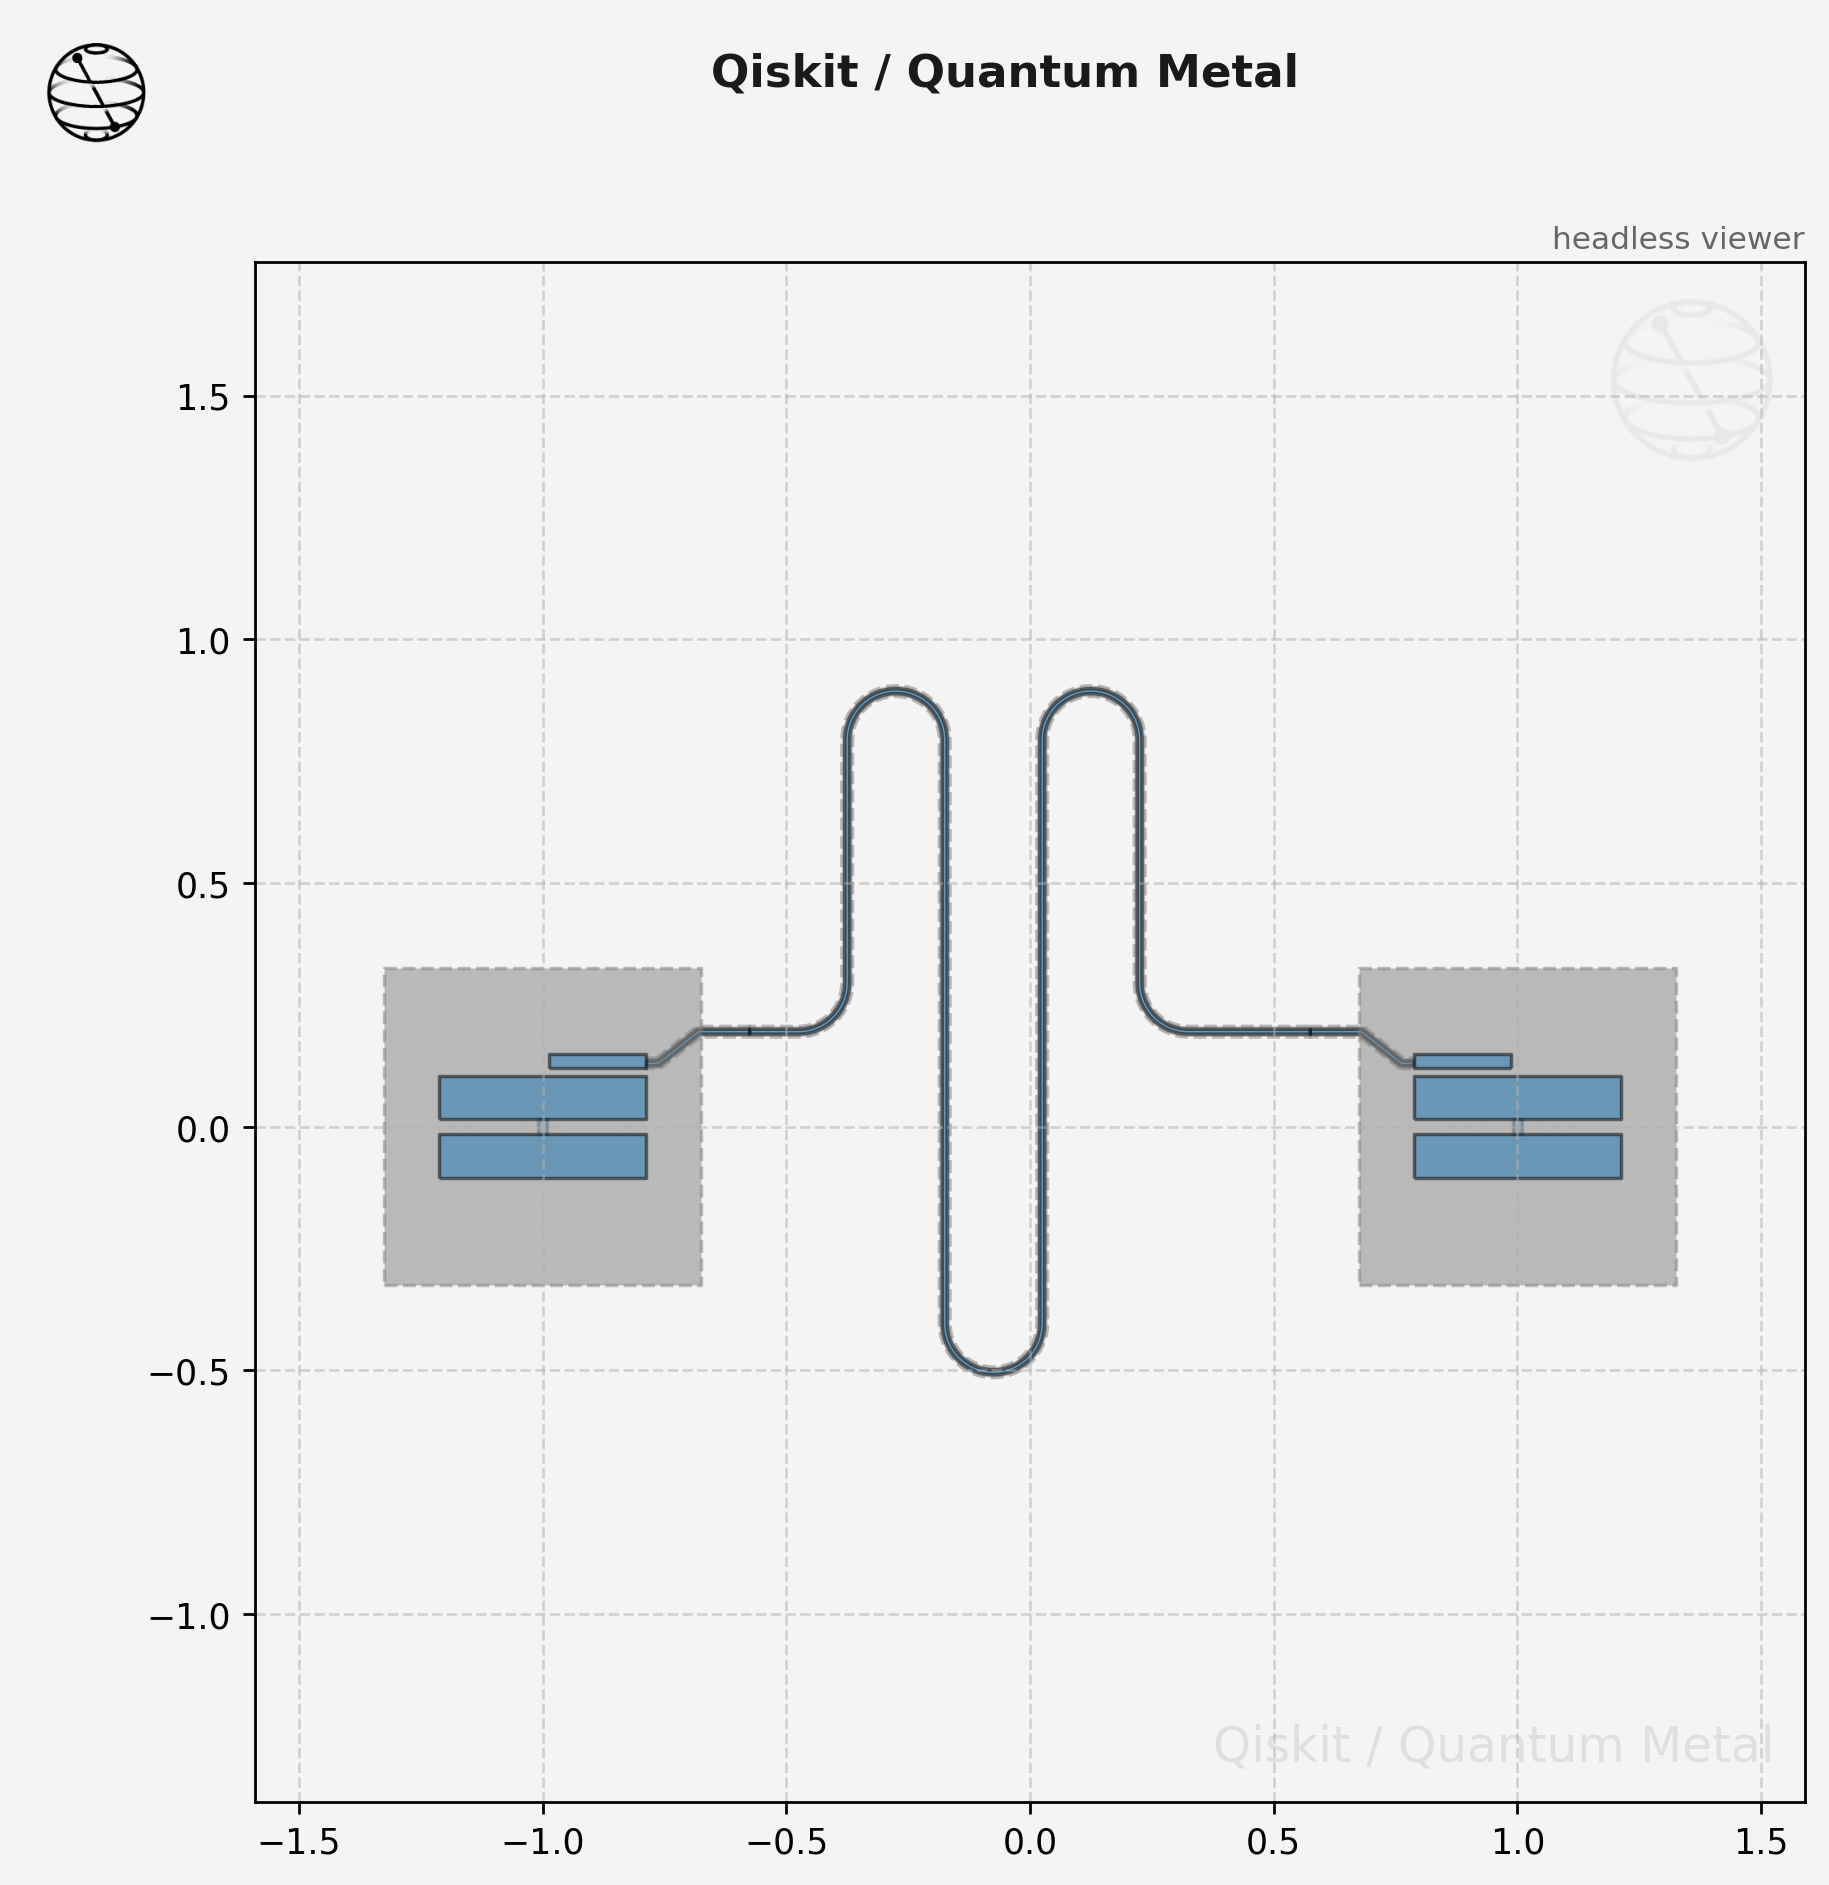

twotransmons.gds: 0.3 MB


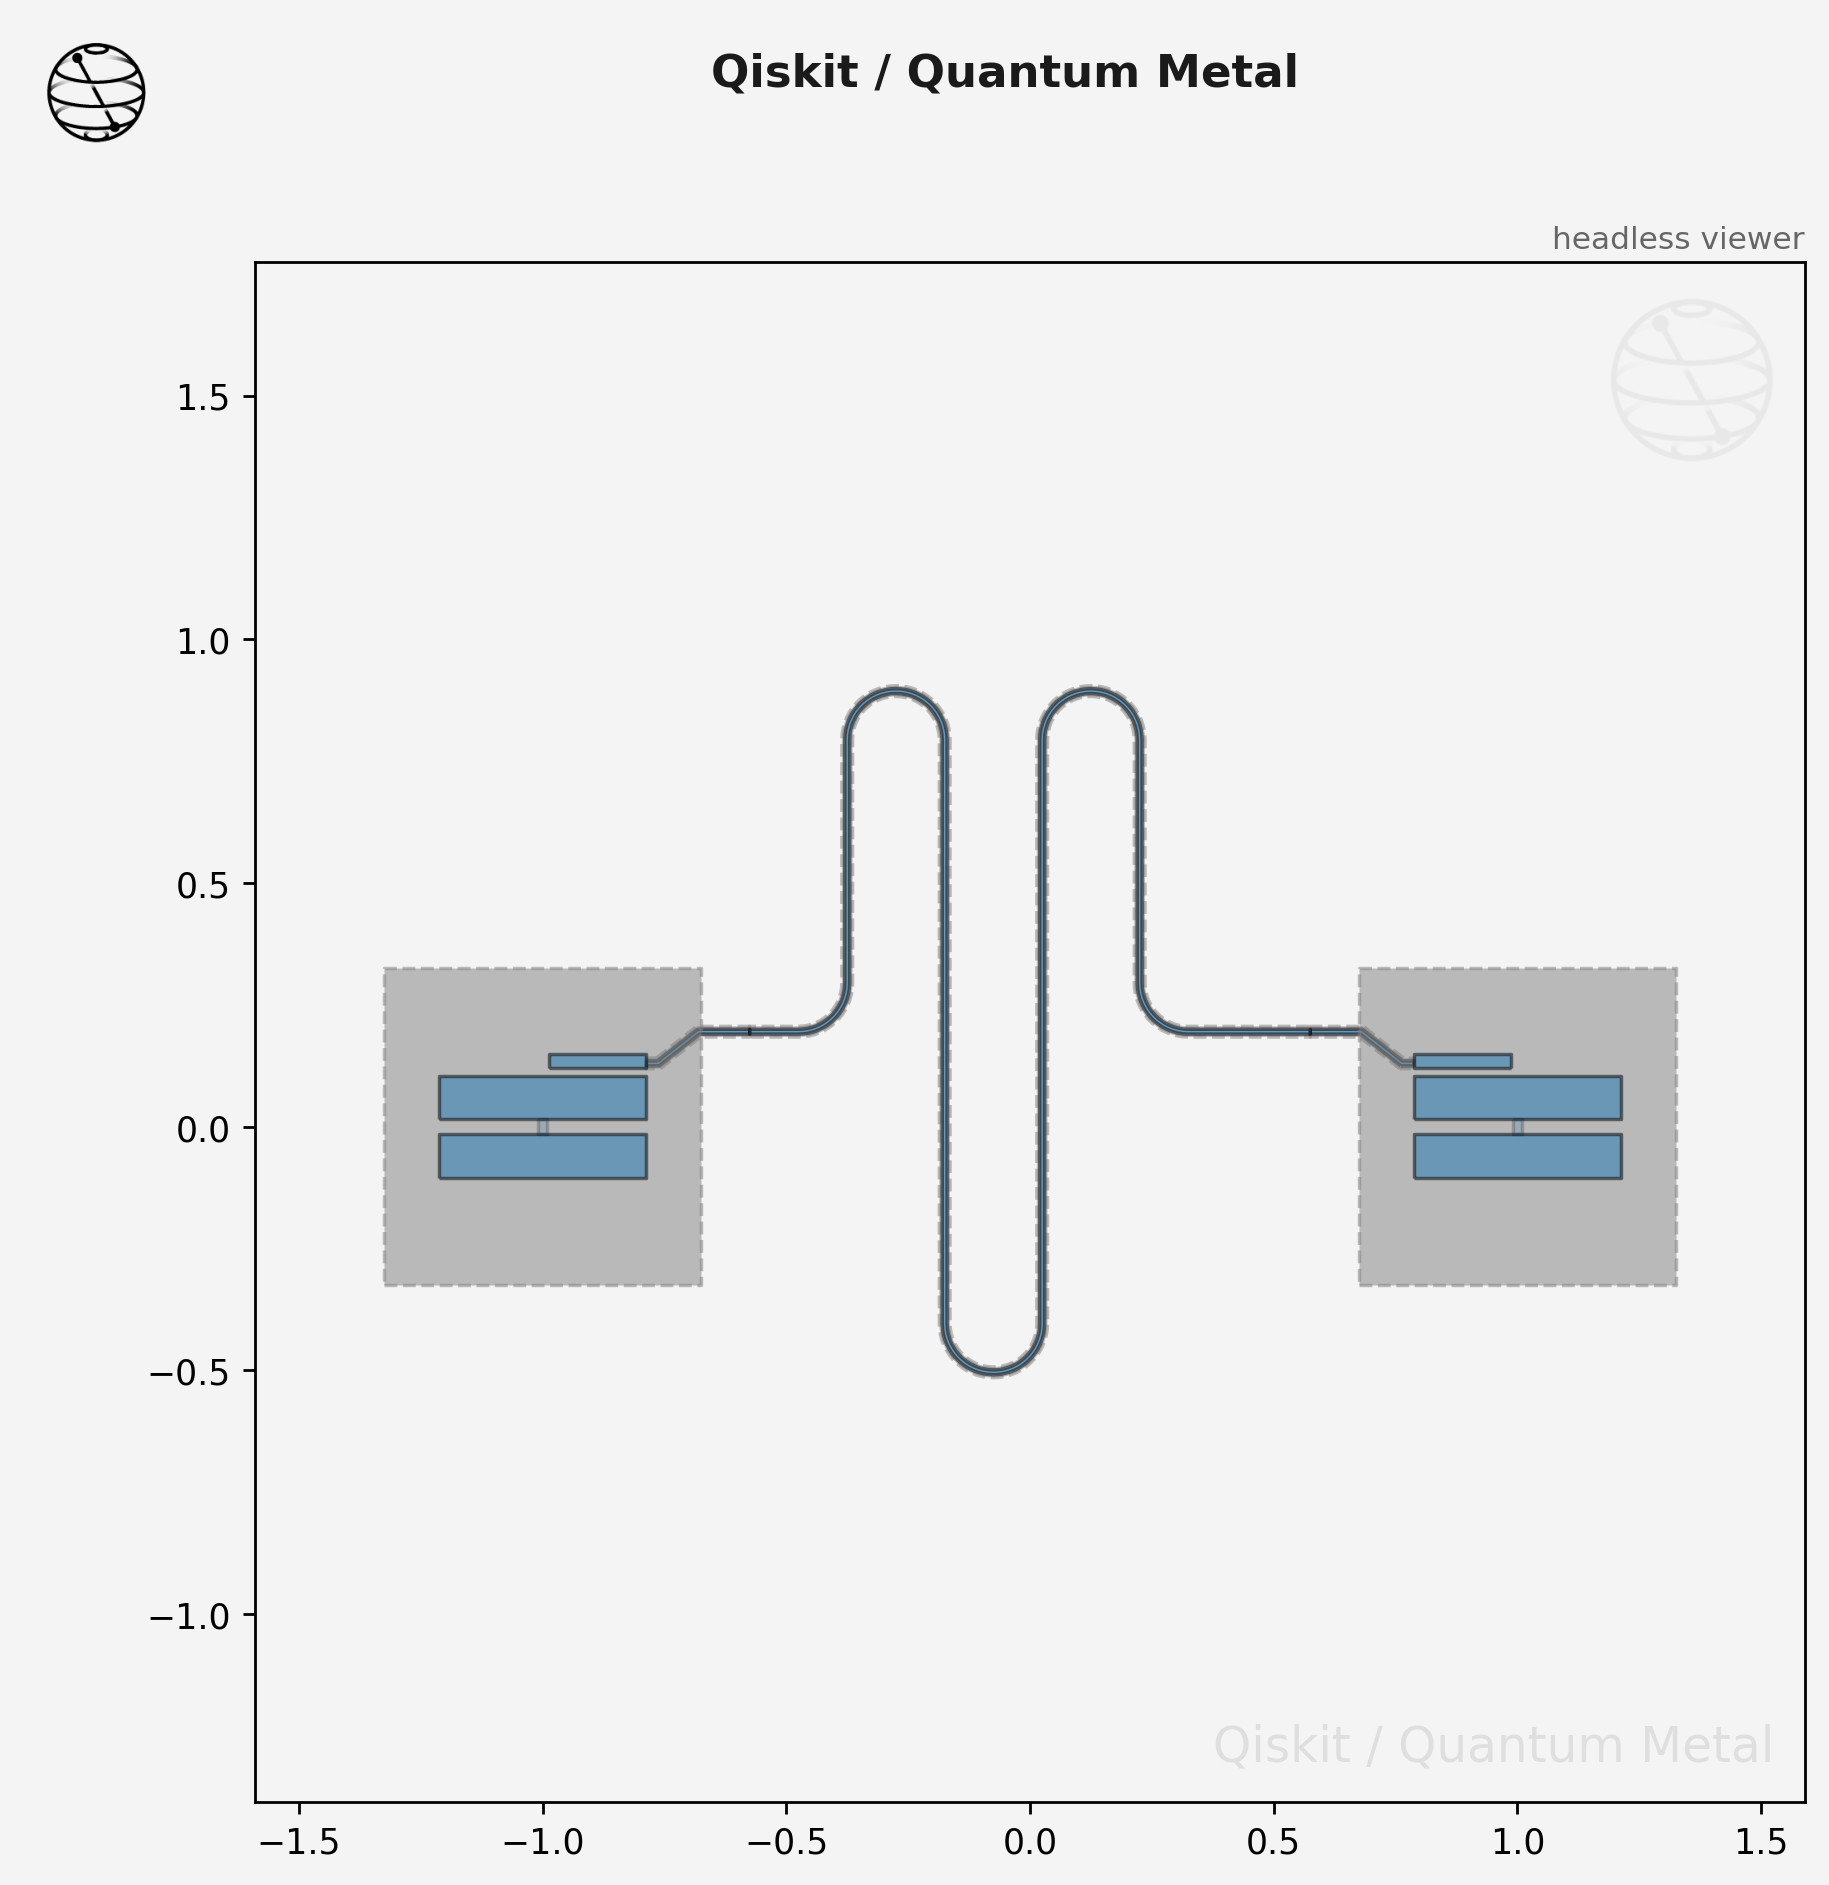

In [53]:
import logging

# Silence matplotlib logging warnings
logging.getLogger('matplotlib').setLevel(logging.ERROR)

# Handle the initial render
if HEADLESS:
    metal.view(design)
else:
    gui.rebuild()
    gui.autoscale()

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Ignoring fixed y limits.*")
    all_component_names = list(design.components.keys())
    gui.zoom_on_components(all_component_names)
    save_headless_screenshot(gui)

# GDS Export Logic
out = Path(tempfile.gettempdir()) / GDS_FILENAME
gds = design.renderers.gds
gds.options.short_segments_to_not_fillet = "True"

level = metal.logger.level
metal.logger.setLevel(logging.ERROR)

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=RuntimeWarning)
    try:
        gds.export_to_gds(str(out))
    finally:
        metal.logger.setLevel(level)

print(f"{out.name}: {out.stat().st_size / 1e6:.1f} MB")
create_download_button(out)

_disp_ops = dict(width=500)
display(Image("shot.png", **_disp_ops))

if not HEADLESS:
    gui.main_window.close()